First 5 rows:
    Loan_ID  Gender Married Dependents     Education Self_Employed  \
0  LP002314  Female      No          0  Not Graduate            No   
1  LP002315    Male     Yes          1      Graduate            No   
2  LP002317    Male     Yes         3+      Graduate            No   
3  LP002318  Female      No          1  Not Graduate           Yes   
4  LP002319    Male     Yes          0      Graduate           NaN   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             2213                0.0        66.0             360.0   
1             8300                0.0       152.0             300.0   
2            81000                0.0       360.0             360.0   
3             3867                0.0        62.0             360.0   
4             6256                0.0       160.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Rural           Y  
1             0.0     Semiurban           N  


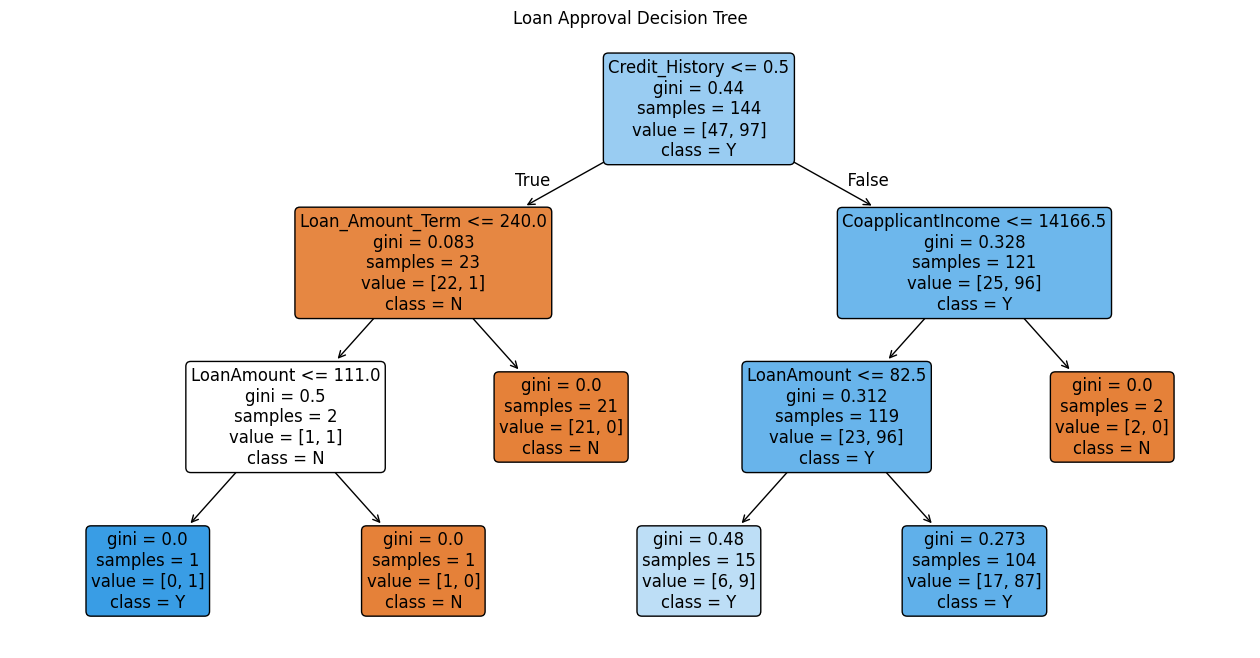


Model Evaluation:
Accuracy: 0.8571
Precision: 0.84
Recall: 0.9767
F1 Score: 0.9032


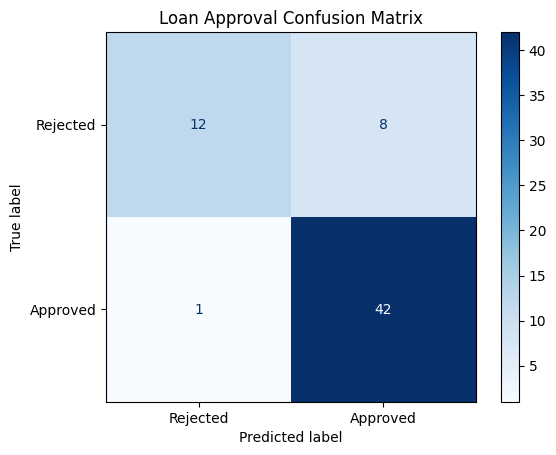

In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

# 1. Load dataset
df = pd.read_excel("/content/loan.xlsx")

print("First 5 rows:")
print(df.head())

print("\nMissing values:")
print(df.isnull().sum())

# 2. Handle missing values
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# 3. Remove unnecessary ID column
df = df.drop("Loan_ID", axis=1)

# 4. Convert categorical columns into numeric columns
df = pd.get_dummies(
    df,
    columns=[
        "Gender", "Married", "Dependents", "Education",
        "Self_Employed", "Property_Area"
    ],
    drop_first=True,
    dtype=int
)

# 5. Select input features and target
X = df.drop("Loan_Status", axis=1)
y = df["Loan_Status"]

# 6. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# 7. Train Decision Tree
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

# 8. Predict loan status
y_pred = model.predict(X_test)

print("\nActual vs Predicted:")
print(pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
}).to_string(index=False))

# 9. Visualize Decision Tree
plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True
)

plt.title("Loan Approval Decision Tree")
plt.show()

# 10. Evaluate model
print("\nModel Evaluation:")

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("Precision:", round(precision_score(
    y_test, y_pred, pos_label="Y", zero_division=0
), 4))

print("Recall:", round(recall_score(
    y_test, y_pred, pos_label="Y", zero_division=0
), 4))

print("F1 Score:", round(f1_score(
    y_test, y_pred, pos_label="Y", zero_division=0
), 4))

# 11. Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=["N", "Y"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected", "Approved"]
)

disp.plot(cmap="Blues")
plt.title("Loan Approval Confusion Matrix")
plt.show()
